# **Import Libraries**

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
# For Stats
from scipy.stats import wilcoxon, rankdata, mannwhitneyu, chi2_contingency, fisher_exact, binomtest
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import SquareTable

# **Data Processing**

In [ ]:
version_1 = pd.read_csv("/content/LeafTutor User Experience Survey Version 1_Submissions_2026-11-15.csv")
version_2 = pd.read_csv("/content/LeafTutor User Experience Survey Version 2_Submissions_2026-11-15.csv")

In [ ]:
version_1.head()

,Submission ID,Respondent ID,Submitted at,What best describes your role?,What best describes your role? (Instructor),What best describes your role? (Student),What best describes your role? (Other (please specify)),"If other, please specify",Untitled checkboxes field,Untitled checkboxes field (Conversation Mode),...,Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The assignment/project area was easy to understand and use.],Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The AI tutoring/chat area was easy to understand and use.],Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The LeafTutor design was visually appealing.],"Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [\nOverall, I found LeafTutor easy to use.]",How long did it take you to become comfortable using LeafTutor without assistance?,Were you able to successfully complete the task you intended to perform using LeafTutor?,Section 3 of 4: Retention & Switching Behavior,Is there anything that influenced your rating? (Optional),Were you able to achieve your goal using LeafTutor alone?,What obstacle most affected your ability to complete your task?
0,8N44RM5,xXWy6b9,2026-11-06 17:06:29,Student,False,True,False,NaN,Conversation Mode,True,...,3,4,2,3,1-3 minutes,Yes,4,NaN,Yes,navigating the website
1,o9LLv1P,xXWy6b9,2026-11-06 17:10:13,Student,False,True,False,NaN,Conversation Mode,True,...,2,3,2,1 (Strongly Disagree),4-5 minutes,Partially,3,NaN,Partially,Having to figure out on your own on how to use...
2,lakkzJ5,xXWy6b9,2026-11-06 17:14:02,Student,False,True,False,NaN,Conversation Mode,True,...,2,4,4,3,More than 5 minutes,Yes,3,NaN,Yes,not entirely understanding how to operate it
3,Dq66byb,xXWy6b9,2026-11-06 17:18:40,Student,False,True,False,NaN,Conversation Mode,True,...,3,5 (Strongly Agree),2,3,1-3 minutes,Partially,3,NaN,Partially,How clear the task is
4,Z9rMG6V,vGREDvQ,2026-11-07 02:55:44,Student,False,True,False,NaN,Deep Coding Mode,False,...,2,1 (Strongly Disagree),2,1 (Strongly Disagree),I never became comfortable,No,1,NaN,No,The structure on the webpage was confusing


In [ ]:
version_1.columns

Index(['Submission ID', 'Respondent ID', 'Submitted at',
       'What best describes your role?',
       'What best describes your role? (Instructor)',
       'What best describes your role? (Student)',
       'What best describes your role? (Other (please specify))',
       'If other, please specify', 'Untitled checkboxes field',
       'Untitled checkboxes field (Conversation Mode)',
       'Untitled checkboxes field (Deep Coding Mode)',
       'Untitled checkboxes field (Both)', 'Untitled multiple choice field',
       'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The LeafTutor interface was easy to understand]',
       'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [It was easy to navigate through LeafTutor]',
       'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [I could easily find the features I needed]',
       'Please rate the following statements from 1 (S

In [ ]:
version_1.shape

(21, 28)

In [ ]:
version_1.describe()

,Section 3 of 4: Retention & Switching Behavior
count,21.000000
mean,2.571429
std,0.870140
min,1.000000
25%,2.000000
50%,3.000000
75%,3.000000
max,4.000000


In [ ]:
# Remove the first participant from version_1 because didn't complete version_2 survey
version_1_filtered = version_1.iloc[1:].reset_index(drop=True)

print(version_1_filtered.shape)

(20, 28)


In [ ]:
version_2.head()

,Submission ID,Respondent ID,Submitted at,What best describes your role?,What best describes your role? (Instructor),What best describes your role? (Student),What best describes your role? (Other (please specify)),"If other, please specify",Untitled checkboxes field,Untitled checkboxes field (Conversation Mode),...,Is there anything that influenced your rating? (Optional),Were you able to achieve your goal using LeafTutor alone?,What obstacle most affected your ability to complete your task?,Which platform (original model or updated model) do you liked the best,"Based solely on the user interface and user experience, how long would you continue using LeafTutor before considering a different AI platform?",LeafTutor usability,Untitled long answer field,What did you like the most about using LeafTutor?,What feature most helped you accomplish your goal while using LeafTutor?,What obstacle most affected your ability to complete your task? (2)
0,M1l62R0,EkODaaX,2026-10-12 23:10:16,"Other (please specify), Instructor",True,False,True,na,Conversation Mode,True,...,NaN,NaN,NaN,NaN,5-15 minutes,Practicing coding skills,NaN,Like the idea but hard to navigate.,A lot of information at once and no guide on h...,Give the site more structure and make items mo...
1,6DGWYWJ,xXWy6b9,2026-10-12 23:11:58,Student,False,True,False,NaN,Both,False,...,The interface was confusing to use. Not easy t...,NaN,NaN,NaN,5-15 minutes,Receiving tutoring assistance,For tutoring assistance.,It provided help.,It was difficult not to see the assignments wh...,Changing the layout.
2,e5WWyWJ,RGOZPPj,2026-11-06 17:19:11,Student,False,True,False,NaN,Conversation Mode,True,...,NaN,Yes,NaN,Updated Model,NaN,NaN,NaN,NaN,NaN,NaN
3,o9LLpd5,RGOZPPj,2026-11-06 17:20:59,Student,False,True,False,NaN,Both,False,...,NaN,Partially,Just how clear the task was,Updated Model,NaN,NaN,NaN,NaN,NaN,NaN
4,kbBok0r,1AjG6Mp,2026-11-06 22:55:18,Other (please specify),False,False,True,Nurse,Conversation Mode,True,...,NaN,Partially,Everything was felt cramped and hard to read.,Updated Model,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
version_2.columns

Index(['Submission ID', 'Respondent ID', 'Submitted at',
       'What best describes your role?',
       'What best describes your role? (Instructor)',
       'What best describes your role? (Student)',
       'What best describes your role? (Other (please specify))',
       'If other, please specify', 'Untitled checkboxes field',
       'Untitled checkboxes field (Conversation Mode)',
       'Untitled checkboxes field (Deep Coding Mode)',
       'Untitled checkboxes field (Both)', 'Untitled multiple choice field',
       'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The LeafTutor interface was easy to understand]',
       'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [It was easy to navigate through LeafTutor]',
       'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [I could easily find the features I needed]',
       'Please rate the following statements from 1 (S

In [ ]:
version_2.shape

(22, 35)

In [ ]:
version_2.describe()

,Section 3 of 4: Retention & Switching Behavior
count,22.000000
mean,4.272727
std,1.162174
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [ ]:
platform_question = "Which platform (original model or updated model) do you liked the best"

# Keep only participants who answered the platform question
version_2_filtered = version_2.dropna(subset=[platform_question])

print(version_2_filtered.shape)

(20, 35)


# **Usability (Rate questions)**

In [ ]:
# Map the actual column names in version_1 to their corresponding HCI Areas
column_to_hci = {
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The LeafTutor interface was easy to understand]': 'Learnability: Easy to understand',
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [It was easy to navigate through LeafTutor]': 'Ease of Navigation',
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [I could easily find the features I needed]': 'Efficiency: Find features needed',
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The layout and organization were clear]': 'Layout and Organization was clear',
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [I could easily identify what I was supposed to do when using LeafTutor]': 'Task Clarity',
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The assignment/project area was easy to understand and use.]': 'Assignment Area Usability',
    #'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The AI tutoring/chat area was easy to understand and use.]': 'Interaction Usability',
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The LeafTutor design was visually appealing.]': 'Aesthetic Design',
    'Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [\nOverall, I found LeafTutor easy to use.]': 'Overall easy to use'
}

# Helper function to extract the numeric score from rating text (e.g. "1 (Strongly Disagree)" -> 1.0)
def get_clean_mean(df, column):
    # Extract digits, convert to numeric, and calculate mean
    numeric_series = pd.to_numeric(df[column].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
    return numeric_series.mean()

hci_results_1 = pd.DataFrame({
    "HCI Area": list(column_to_hci.values()),
    "Question": list(column_to_hci.keys()),
    "Average Rating": [
        get_clean_mean(version_1_filtered, q) for q in column_to_hci.keys()
    ]
})

print(hci_results_1)

                            HCI Area  \
0   Learnability: Easy to understand   
1                 Ease of Navigation   
2   Efficiency: Find features needed   
3  Layout and Organization was clear   
4                       Task Clarity   
5          Assignment Area Usability   
6                   Aesthetic Design   
7                Overall easy to use   

                                            Question  Average Rating  
0  Please rate the following statements from 1 (S...            2.40  
1  Please rate the following statements from 1 (S...            2.60  
2  Please rate the following statements from 1 (S...            2.15  
3  Please rate the following statements from 1 (S...            2.25  
4  Please rate the following statements from 1 (S...            2.30  
5  Please rate the following statements from 1 (S...            2.40  
6  Please rate the following statements from 1 (S...            2.10  
7  Please rate the following statements from 1 (S...            2.00  


In [ ]:
hci_results_2 = pd.DataFrame({
    "HCI Area": list(column_to_hci.values()),
    "Question": list(column_to_hci.keys()),
    "Average Rating": [
        get_clean_mean(version_2_filtered, q) for q in column_to_hci.keys()
    ]
})

print(hci_results_2)

                            HCI Area  \
0   Learnability: Easy to understand   
1                 Ease of Navigation   
2   Efficiency: Find features needed   
3  Layout and Organization was clear   
4                       Task Clarity   
5          Assignment Area Usability   
6                   Aesthetic Design   
7                Overall easy to use   

                                            Question  Average Rating  
0  Please rate the following statements from 1 (S...            4.40  
1  Please rate the following statements from 1 (S...            4.35  
2  Please rate the following statements from 1 (S...            4.20  
3  Please rate the following statements from 1 (S...            4.45  
4  Please rate the following statements from 1 (S...            4.15  
5  Please rate the following statements from 1 (S...            4.35  
6  Please rate the following statements from 1 (S...            4.45  
7  Please rate the following statements from 1 (S...            4.35  


## Plot

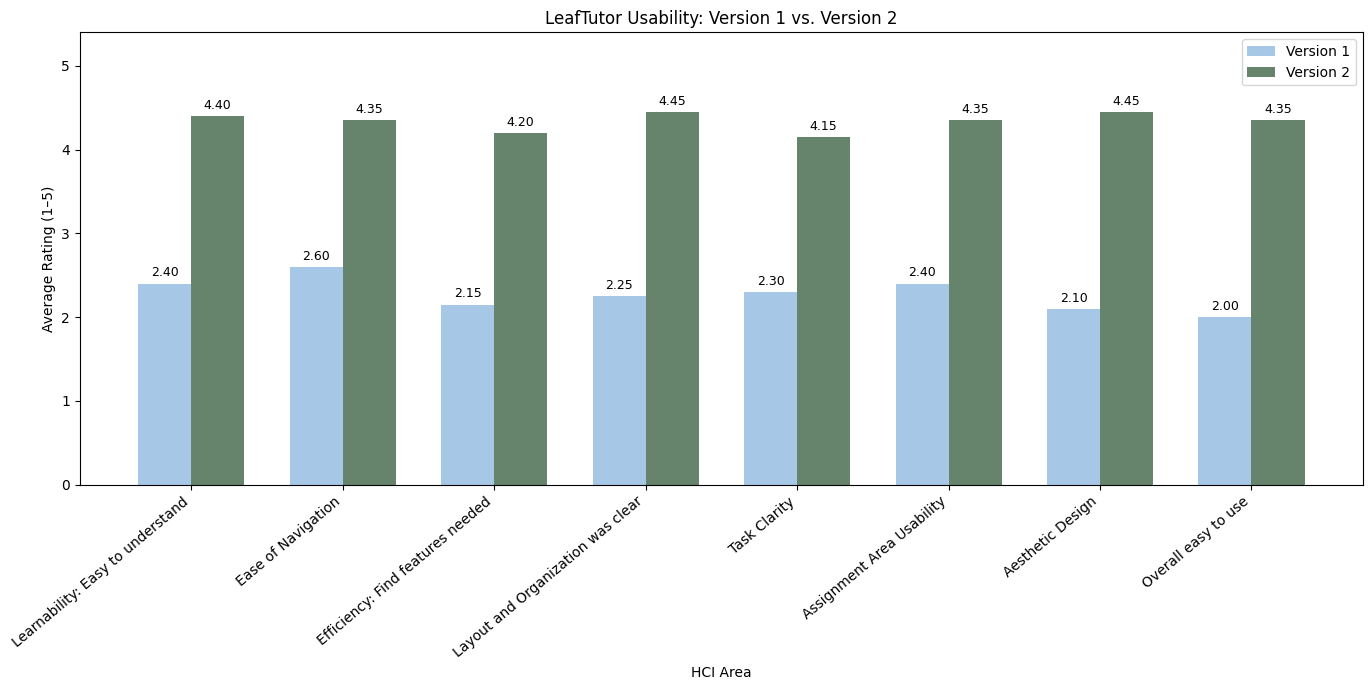

In [ ]:
# Get HCI categories
categories = hci_results_1["HCI Area"]

# Get average ratings
before = hci_results_1["Average Rating"]
after = hci_results_2["Average Rating"]

# Set bar positions
x = np.arange(len(categories))
width = 0.35

# Create graph
plt.figure(figsize=(14, 7))

bars1 = plt.bar(x - width/2, before, width, label="Version 1", color = '#A7C7E7')
bars2 = plt.bar(x + width/2, after, width, label="Version 2", color='#66836c')

# Add values above each bar
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.05,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

# Formatting
plt.ylim(0, 5.4)
plt.xlabel("HCI Area")
plt.ylabel("Average Rating (1–5)")
plt.title("LeafTutor Usability: Version 1 vs. Version 2")

plt.xticks(x, categories, rotation=40, ha="right")
plt.legend(loc="upper right")

plt.tight_layout()
plt.savefig("result_HCI.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
hci_questions = {
    "Learnability": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The LeafTutor interface was easy to understand]",

    "Navigation": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [It was easy to navigate through LeafTutor]",

    "Efficiency": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [I could easily find the features I needed]",

    "Consistency and Design": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The layout and organization were clear]",

    "Visibility and Guidance": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [I could easily identify what I was supposed to do when using LeafTutor]",

    "Task Usability": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The assignment/project area was easy to understand and use.]",

    "Interaction Usability": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The AI tutoring/chat area was easy to understand and use.]",

    "Aesthetic Design": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [The LeafTutor design was visually appealing.]",

    "Overall Satisfaction": "Please rate the following statements from 1 (Strongly Disagree) to 5 (Strongly Agree) [\nOverall, I found LeafTutor easy to use.]"
}

## *Stat Tests (Mann–Whitney U)*

In [ ]:
def clean_rating(series):
    extracted = series.astype(str).str.extract(
        r'^\s*([1-5])(?:\.0+)?(?:\s|$)'
    )[0]
    return pd.to_numeric(extracted, errors="coerce")


results = []

for question, area in column_to_hci.items():

    # Get individual ratings
    original = clean_rating(
        version_1_filtered[question]
    ).dropna()

    updated = clean_rating(
        version_2_filtered[question]
    ).dropna()

    if len(original) == 0 or len(updated) == 0:
        continue

    # Mann-Whitney U test
    stat, p_value = mannwhitneyu(
        updated,
        original,
        alternative="two-sided",
        method="auto"
    )

    # Rank-biserial effect size
    effect_size = (
        (2 * stat) / (len(updated) * len(original))
    ) - 1

    results.append({
        "HCI Area": area,
        "Original N": len(original),
        "Updated N": len(updated),
        "Original Mean": original.mean(),
        "Updated Mean": updated.mean(),
        "Original Median": original.median(),
        "Updated Median": updated.median(),
        "Mean Difference": updated.mean() - original.mean(),
        "U Statistic": stat,
        "Effect Size": effect_size,
        "P-value": p_value
    })


# Results table
results_df = pd.DataFrame(results)

# Holm correction
if not results_df.empty:

    results_df["Adjusted P-value"] = multipletests(
        results_df["P-value"],
        method="holm"
    )[1]

    results_df["Significant"] = (
        results_df["Adjusted P-value"] < 0.05
    )

    results_df = results_df.round(5)

print(results_df.to_string(index=False))

                         HCI Area  Original N  Updated N  Original Mean  Updated Mean  Original Median  Updated Median  Mean Difference  U Statistic  Effect Size  P-value  Adjusted P-value  Significant
 Learnability: Easy to understand          20         20           2.40          4.40              2.0             5.0             2.00        351.5       0.7575  0.00002           0.00007         True
               Ease of Navigation          20         20           2.60          4.35              3.0             5.0             1.75        337.5       0.6875  0.00011           0.00017         True
 Efficiency: Find features needed          20         20           2.15          4.20              2.0             5.0             2.05        340.5       0.7025  0.00008           0.00017         True
Layout and Organization was clear          20         20           2.25          4.45              2.0             5.0             2.20        357.0       0.7850  0.00001           0.00005    

# **Task/Goal Question**

In [ ]:
task_question = "Were you able to successfully complete the task you intended to perform using LeafTutor?"

def calculate_success_counts(df, column):

    responses = df[column].dropna().astype(str).str.strip().str.lower()

    successful = responses.isin([
        "yes",
        "yes, successfully"
    ]).sum()

    unsuccessful = len(responses) - successful

    return successful, unsuccessful

In [ ]:
# Calculate the success percentages first
v1_success, v1_fail = calculate_success_counts(version_1_filtered, task_question)
v2_success, v2_fail = calculate_success_counts(version_2_filtered, task_question)

before_task = (v1_success / (v1_success + v1_fail)) * 100
after_task = (v2_success / (v2_success + v2_fail)) * 100

# Create categories
categories = [
    "Successful Task Completion"
]

# Get percentages
before = [before_task]
after = [after_task]

In [ ]:
# Calculate the success counts
v1_success, v1_fail = calculate_success_counts(version_1_filtered, task_question)
v2_success, v2_fail = calculate_success_counts(version_2_filtered, task_question)

# Compute success rates as percentages
before_task = (v1_success / (v1_success + v1_fail)) * 100
after_task = (v2_success / (v2_success + v2_fail)) * 100

## Plot

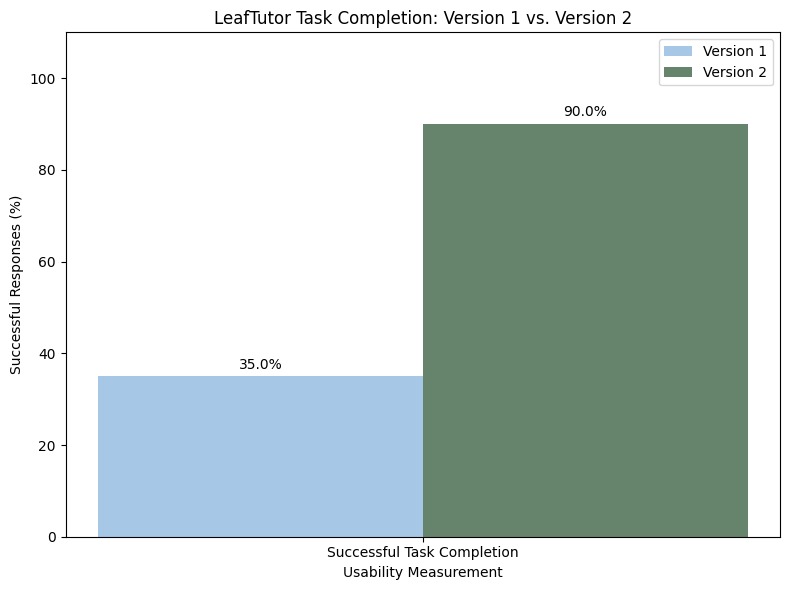

In [ ]:
categories = ["Successful Task Completion"]

before = [before_task]
after = [after_task]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(8, 6))

bars1 = plt.bar(
    x - width/2, before, width,
    label="Version 1",
    color="#A7C7E7"
)

bars2 = plt.bar(
    x + width/2, after, width,
    label="Version 2",
    color="#66836c"
)

# Add percentage labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f"{height:.1f}%",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.ylim(0, 110)
plt.ylabel("Successful Responses (%)")
plt.xlabel("Usability Measurement")
plt.title("LeafTutor Task Completion: Version 1 vs. Version 2")

plt.xticks(x, categories)
plt.legend(loc="upper right")

plt.tight_layout()
plt.savefig("result_task.png", dpi=300, bbox_inches="tight")
plt.show()

## *Stats (Chi-square test)*

In [ ]:
def compare_task_success(question):

    # Get counts
    v1_success, v1_failure = calculate_success_counts(
        version_1_filtered, question
    )

    v2_success, v2_failure = calculate_success_counts(
        version_2_filtered, question
    )

    # Create contingency table
    table = np.array([
        [v1_success, v1_failure],
        [v2_success, v2_failure]
    ])

    # Expected counts
    chi2, chi_p, dof, expected = chi2_contingency(
        table,
        correction=False
    )

    # Select appropriate test
    if (expected < 5).any():
        odds_ratio, p_value = fisher_exact(table)
        test_name = "Fisher's Exact Test"
    else:
        chi2, p_value, dof, expected = chi2_contingency(
            table,
            correction=False
        )
        test_name = "Chi-square Test"

    # Calculate percentages
    v1_total = v1_success + v1_failure
    v2_total = v2_success + v2_failure

    v1_percent = (v1_success / v1_total) * 100
    v2_percent = (v2_success / v2_total) * 100

    return {
        "Question": question,
        "Test": test_name,
        "Version 1 Success": v1_success,
        "Version 1 Failure": v1_failure,
        "Version 1 Success (%)": v1_percent,
        "Version 2 Success": v2_success,
        "Version 2 Failure": v2_failure,
        "Version 2 Success (%)": v2_percent,
        "Difference (%)": v2_percent - v1_percent,
        "P-value": p_value
    }

In [ ]:
task_results = pd.DataFrame([
    compare_task_success(task_question)
])

print(task_results.round(5).to_string(index=False))

                                                                                Question            Test  Version 1 Success  Version 1 Failure  Version 1 Success (%)  Version 2 Success  Version 2 Failure  Version 2 Success (%)  Difference (%)  P-value
Were you able to successfully complete the task you intended to perform using LeafTutor? Chi-square Test                  7                 13                   35.0                 18                  2                   90.0            55.0  0.00033


In [ ]:
task_results["Adjusted P-value"] = multipletests(
    task_results["P-value"],
    method="holm"
)[1]

task_results["Significant"] = (
    task_results["Adjusted P-value"] < 0.05
)

print(task_results.round(5).to_string(index=False))

                                                                                Question            Test  Version 1 Success  Version 1 Failure  Version 1 Success (%)  Version 2 Success  Version 2 Failure  Version 2 Success (%)  Difference (%)  P-value  Adjusted P-value  Significant
Were you able to successfully complete the task you intended to perform using LeafTutor? Chi-square Test                  7                 13                   35.0                 18                  2                   90.0            55.0  0.00033           0.00033         True


# **Which platform**

In [ ]:
platform_question = "Which platform (original model or updated model) do you liked the best"

print(version_2_filtered[platform_question].value_counts(dropna=False))

Which platform (original model or updated model) do you liked the best
Updated Model    20
Name: count, dtype: int64


## Plot

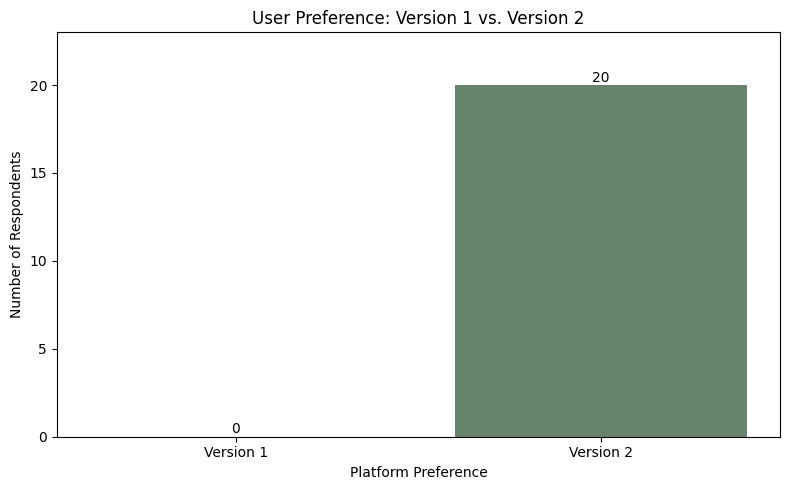

In [ ]:
platform_counts = version_2_filtered[platform_question].dropna().value_counts()

# Include both options, even if one has zero responses
platform_options = ["Original Model", "Updated Model"]
platform_counts = platform_counts.reindex(platform_options, fill_value=0)

platform_counts = platform_counts.rename({
    "Original Model": "Version 1",
    "Updated Model": "Version 2"
})
plt.figure(figsize=(8, 5))


plt.bar(
    platform_counts.index,
    platform_counts.values,
    color=["#A7C7E7", "#66836c"]
)

plt.xlabel("Platform Preference")
plt.ylabel("Number of Respondents")
plt.title("User Preference: Version 1 vs. Version 2")


# Display the count above each bar
for i, count in enumerate(platform_counts.values):
    plt.text(i, count + 0.2, str(count), ha="center")

plt.ylim(0, max(platform_counts.values) + 3)

plt.tight_layout()
plt.savefig("result_preference.png", dpi=300, bbox_inches="tight")
plt.show()

## *Stats (Binomial Test)*

In [ ]:
# Remove missing responses
preferences = version_2_filtered[platform_question].dropna()

# Count preferences
updated_count = (preferences == "Updated Model").sum()
original_count = (preferences == "Original Model").sum()

total_responses = updated_count + original_count

# Exact binomial test
result = binomtest(
    updated_count,
    total_responses,
    p=0.5,
    alternative="two-sided"
)

print("Updated Model:", updated_count)
print("Original Model:", original_count)
print("Total Responses:", total_responses)
print("P-value:", result.pvalue)

Updated Model: 20
Original Model: 0
Total Responses: 20
P-value: 1.9073486328125e-06


# **Time Question**

In [ ]:
comfort_question = "How long did it take you to become comfortable using LeafTutor without assistance?"

categories = version_2_filtered[comfort_question].dropna().unique().tolist()

print(categories)

['Less than 1 minute', '1-3 minutes', 'I never became comfortable', 'More than 5 minutes', '4-5 minutes']


## Plot

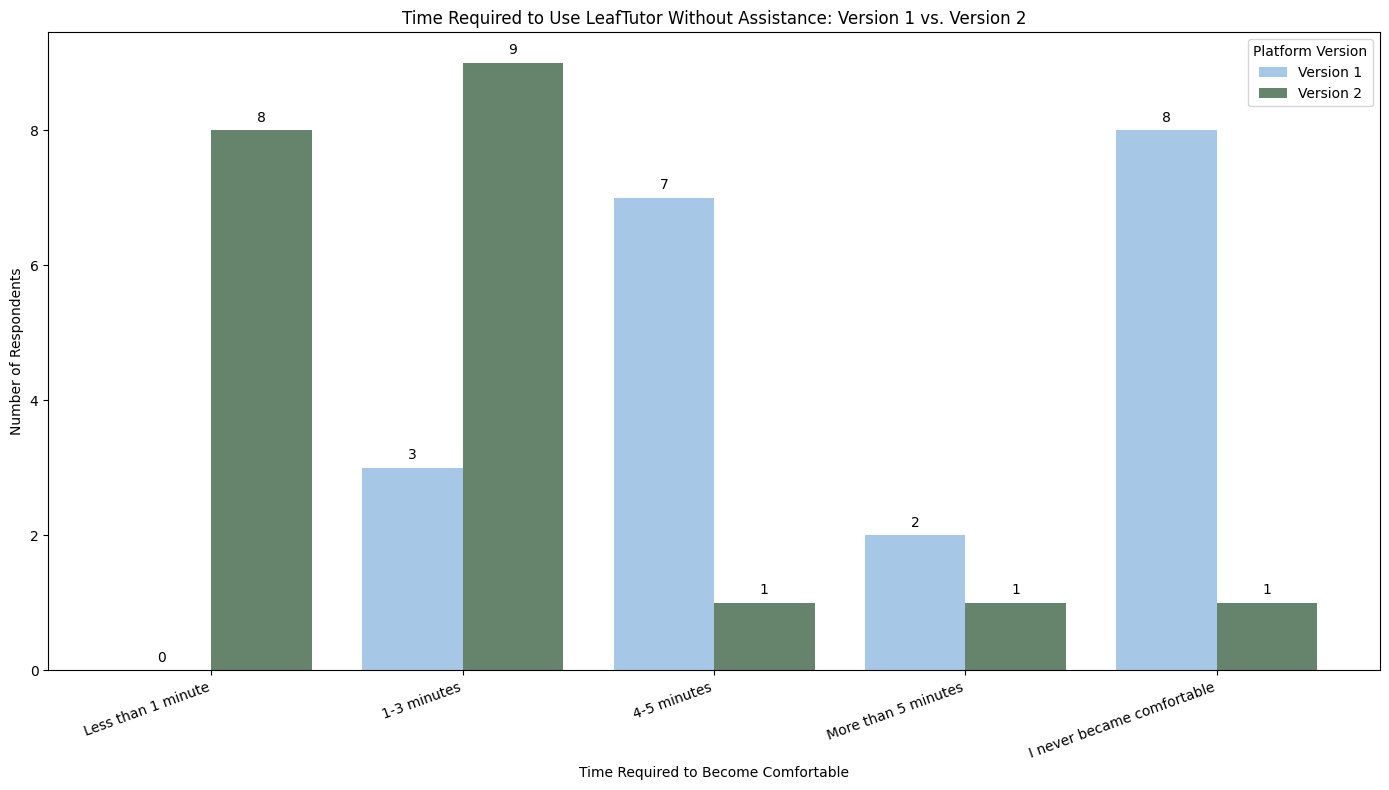

In [ ]:
comfort_question = "How long did it take you to become comfortable using LeafTutor without assistance?"

# Preserve the intended order, including categories with zero responses
categories = [
    "Less than 1 minute",
    "1-3 minutes",
    "4-5 minutes",
    "More than 5 minutes",
    "I never became comfortable"
]

before = (
    version_1_filtered[comfort_question]
    .value_counts()
    .reindex(categories, fill_value=0)
)

after = (
    version_2_filtered[comfort_question]
    .value_counts()
    .reindex(categories, fill_value=0)
)

# Combine response categories
comfort_counts = pd.DataFrame({
    "Version 1": before,
    "Version 2": after
}).fillna(0)

# Plot
ax = comfort_counts.plot(
    kind="bar",
    figsize=(14, 8),
    width=0.8,
    color=["#A7C7E7", "#66836c"]
)

plt.xlabel("Time Required to Become Comfortable")
plt.ylabel("Number of Respondents")
plt.title("Time Required to Use LeafTutor Without Assistance: Version 1 vs. Version 2")

# Display response counts above individual bars
for p in ax.patches:
    val = int(p.get_height())
    ax.annotate(str(val),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points')

plt.xticks(rotation=20, ha="right")
plt.legend(title="Platform Version", loc="upper right")
plt.tight_layout()
plt.savefig("result_time.png", dpi=300, bbox_inches="tight")
plt.show()

## *Stats (Mann–Whitney U)*

In [ ]:
# Define the comfort question column name
comfort_question = "How long did it take you to become comfortable using LeafTutor without assistance?"

# Map comfort categories to numeric values for Mann-Whitney U test
comfort_mapping = {
    "Less than 1 minute": 1,
    "1-3 minutes": 2,
    "4-5 minutes": 3,
    "More than 5 minutes": 4,
    "I never became comfortable": 5
}

# Extract responses and map them
comfort_v1_numeric = version_1_filtered[comfort_question].dropna().map(comfort_mapping)
comfort_v2_numeric = version_2_filtered[comfort_question].dropna().map(comfort_mapping)

# Mann-Whitney U test
stat, p_value = mannwhitneyu(
    comfort_v2_numeric,
    comfort_v1_numeric,
    alternative="two-sided"
)

# Print results
print("Version 1 responses:", len(comfort_v1_numeric))
print("Version 2 responses:", len(comfort_v2_numeric))
print("Version 1 median rank:", comfort_v1_numeric.median())
print("Version 2 median rank:", comfort_v2_numeric.median())
print("U statistic:", stat)
print("P-value:", p_value)

Version 1 responses: 20
Version 2 responses: 20
Version 1 median rank: 3.5
Version 2 median rank: 2.0
U statistic: 47.0
P-value: 2.2179592074123486e-05


# **Overall rating**

## Plot

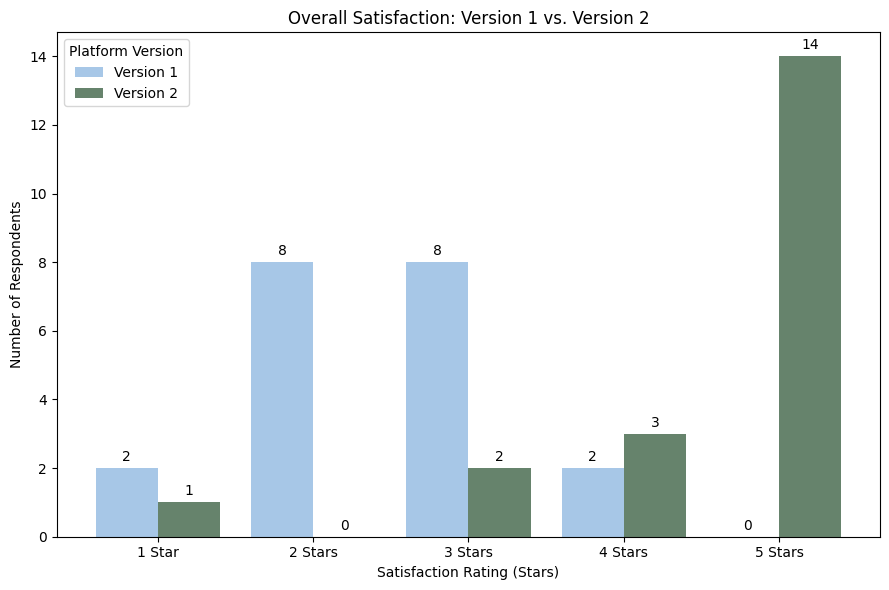

In [ ]:
satisfaction_question = "Section 3 of 4: Retention & Switching Behavior"

# Count ratings
before = version_1_filtered[satisfaction_question].value_counts()
after = version_2_filtered[satisfaction_question].value_counts()

# Keep all ratings from 1 to 5
ratings = [1, 2, 3, 4, 5]

satisfaction_counts = pd.DataFrame({
    "Version 1": before,
    "Version 2": after
}).reindex(ratings, fill_value=0)

# Plot
ax = satisfaction_counts.plot(
    kind="bar",
    figsize=(9, 6),
    width=0.8,
    color=["#A7C7E7", "#66836c"]
)

# Add respondent counts above each bar
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.xlabel("Satisfaction Rating (Stars)")
plt.ylabel("Number of Respondents")
plt.title("Overall Satisfaction: Version 1 vs. Version 2")

plt.xticks(
    ticks=np.arange(5),
    labels=["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"],
    rotation=0
)

plt.legend(title="Platform Version", loc="upper left")

plt.tight_layout()
plt.savefig("result_satisfaction.png", dpi=300, bbox_inches="tight")
plt.show()

## *Stats (Mann–Whitney U test)*

In [ ]:
# Clean satisfaction ratings
before = pd.to_numeric(
    version_1_filtered[satisfaction_question],
    errors="coerce"
).dropna()

after = pd.to_numeric(
    version_2_filtered[satisfaction_question],
    errors="coerce"
).dropna()

# Mann-Whitney U test
stat, p_value = mannwhitneyu(
    before,
    after,
    alternative="two-sided"
)

print("Version 1 responses:", len(before))
print("Version 2 responses:", len(after))

print("Version 1 median:", before.median())
print("Version 2 median:", after.median())

print("Version 1 mean:", before.mean())
print("Version 2 mean:", after.mean())

print("U statistic:", stat)
print("P-value:", p_value)

Version 1 responses: 20
Version 2 responses: 20
Version 1 median: 2.5
Version 2 median: 5.0
Version 1 mean: 2.5
Version 2 mean: 4.45
U statistic: 34.0
P-value: 3.518658547273491e-06


# Usability Nielsen Heuristic (not official)



In [ ]:
prefix = (
    'Please rate the following statements from 1 '
    '(Strongly Disagree) to 5 (Strongly Agree) ['
)

# True = use only the first (primary) heuristic assigned
# False = include all assigned heuristics
PRIMARY_ONLY = False


In [ ]:
item_to_heuristic = {

    'The LeafTutor interface was easy to understand]': [
        'Match Between System and Real World',
        'Recognition Rather Than Recall'
    ],

    'It was easy to navigate through LeafTutor]': [
        'Recognition Rather Than Recall',
        'User Control and Freedom'
    ],

    'I could easily find the features I needed]': [
        'Recognition Rather Than Recall',
        'Flexibility and Efficiency of Use'
    ],

    'The layout and organization were clear]': [
        'Consistency and Standards',
        'Aesthetic and Minimalist Design'
    ],

    'I could easily identify what I was supposed to do when using LeafTutor]': [
        'Visibility of System Status',
        'Help and Documentation'
    ],

    'The assignment/project area was easy to understand and use.]': [
        'Consistency and Standards',
        'Recognition Rather Than Recall'
    ],

    'The AI tutoring/chat area was easy to understand and use.]': [
        'Match Between System and Real World',
        'Recognition Rather Than Recall'
    ],

    'The LeafTutor design was visually appealing.]': [
        'Aesthetic and Minimalist Design'
    ]
}


# Nielsen's standard heuristic order
heuristic_order = [
    'Visibility of System Status',
    'Match Between System and Real World',
    'User Control and Freedom',
    'Consistency and Standards',
    'Recognition Rather Than Recall',
    'Flexibility and Efficiency of Use',
    'Aesthetic and Minimalist Design',
    'Help and Documentation'
]


## Stats

In [ ]:
def clean_rating(series):

    """
    Converts:
    '1 (Strongly Disagree)' -> 1
    '5 (Strongly Agree)' -> 5

    Invalid or missing responses become NaN.
    """

    extracted = series.astype(str).str.extract(
        r'^\s*([1-5])(?:\.0+)?(?=\s|$)'
    )[0]

    return pd.to_numeric(extracted, errors='coerce')

# Calculate heuristic scores

def scores_all(df, primary_only=False):

    """
    Each row represents one participant submission.

    Calculates the average rating for each heuristic.
    No Respondent ID matching or deduplication is performed.

    When a heuristic has multiple assigned questions,
    all assigned questions must have valid ratings.
    """

    parts = {}

    for suffix, heuristics in item_to_heuristic.items():

        col = prefix + suffix

        if col not in df.columns:
            raise KeyError(
                f"Survey question not found: {col}"
            )

        ratings = clean_rating(df[col])

        selected = (
            heuristics[:1]
            if primary_only
            else heuristics
        )

        for heuristic in selected:

            parts.setdefault(heuristic, []).append(ratings)

    scores = {}

    for heuristic, columns in parts.items():

        combined = pd.concat(columns, axis=1)

        # Require all assigned questions to be answered
        complete = (
            combined.notna().sum(axis=1) == combined.shape[1]
        )

        scores[heuristic] = (
            combined.mean(axis=1).where(complete)
        )

    # After calculating scores, count the questions per heuristic
    question_counts = {
        heuristic: len(columns)
        for heuristic, columns in parts.items()
    }

    return pd.DataFrame(scores), question_counts



# Compare independent groups
def compare_versions(df1, df2, primary_only=False):

    original, question_counts = scores_all(df1, primary_only)
    updated, _ = scores_all(df2, primary_only)

    rows = []

    selected_order = [
        h for h in heuristic_order
        if h in original.columns and h in updated.columns
    ]

    for heuristic in selected_order:

        # Remove missing responses separately
        a = original[heuristic].dropna()  # Original
        b = updated[heuristic].dropna()   # Updated

        n_orig = len(a)
        n_upd = len(b)

        if n_orig == 0 or n_upd == 0:
            continue

        # Mann-Whitney U / Wilcoxon rank-sum test
        test = mannwhitneyu(
            b,
            a,
            alternative='two-sided',
            method='auto'
        )

        u = test.statistic
        p_value = test.pvalue

        # Rank-biserial correlation
        # Positive = updated ratings tend to be higher
        # Negative = original ratings tend to be higher

        effect = (
            (2 * u) / (n_upd * n_orig)
        ) - 1

        rows.append({

            'Heuristic': heuristic,
            'Number of Questions': question_counts[heuristic],

            'n (orig)': n_orig,
            'n (upd)': n_upd,

            'Original Mean': a.mean(),
            'Updated Mean': b.mean(),

            'Original Median': a.median(),
            'Updated Median': b.median(),

            'Mean Change': b.mean() - a.mean(),

            'Effect Size (r)': effect,

            'p-value': p_value
        })

    if not rows:
        raise ValueError(
            "No valid heuristic scores available for comparison."
        )

    results = pd.DataFrame(rows).set_index('Heuristic')

    # Holm correction across all heuristic comparisons
    results['p-value (Holm)'] = multipletests(
        results['p-value'],
        method='holm'
    )[1]

    # Statistical significance after Holm correction
    results['Significant'] = results['p-value (Holm)'] < 0.05

    return results



# Run Stat analysis
result = compare_versions(
    version_1_filtered,
    version_2_filtered,
    primary_only=PRIMARY_ONLY
)

print("\nLEAFTUTOR NIELSEN HEURISTIC RESULTS")
print(result.to_string(float_format=lambda x: f"{x:.6f}"))


LEAFTUTOR NIELSEN HEURISTIC RESULTS
                                     Number of Questions  n (orig)  n (upd)  Original Mean  Updated Mean  Original Median  Updated Median  Mean Change  Effect Size (r)  p-value  p-value (Holm)  Significant
Heuristic                                                                                                                                                                                                    
Visibility of System Status                            1        20       20       2.300000      4.150000         2.500000        4.500000     1.850000         0.780000 0.000015        0.000062         True
Match Between System and Real World                    2        20       20       2.425000      4.425000         2.250000        5.000000     2.000000         0.827500 0.000006        0.000033         True
User Control and Freedom                               1        20       20       2.600000      4.350000         3.000000        5.000000  

## Plot

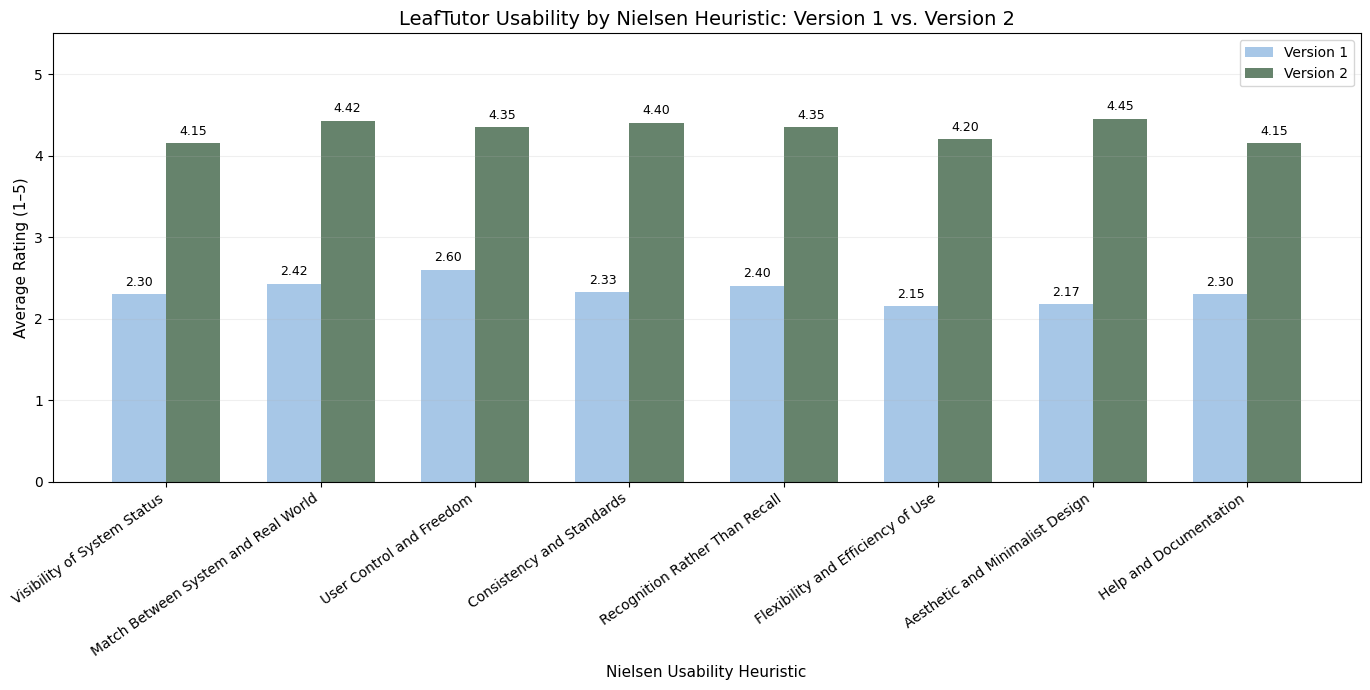

In [ ]:
plot_df = result.copy()

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 7))

bars1 = ax.bar(
    x - width / 2,
    plot_df['Original Mean'],
    width,
    label=f'Version 1',
    color='#A7C7E7'
)

bars2 = ax.bar(
    x + width / 2,
    plot_df['Updated Mean'],
    width,
    label=f'Version 2',
    color='#66836c'
)

# Add average rating labels above bars
for bars in (bars1, bars2):

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f'{height:.2f}',
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=9
        )


# Add sample sizes for each heuristic to x-axis labels
labels = [
    f"{h}"
    for h, row in plot_df.iterrows()
]

ax.set_title(
    'LeafTutor Usability by Nielsen Heuristic: '
    'Version 1 vs. Version 2',
    fontsize=14
)

ax.set_xlabel(
    'Nielsen Usability Heuristic',
    fontsize=11
)

ax.set_ylabel(
    'Average Rating (1–5)',
    fontsize=11
)

ax.set_xticks(x)
ax.set_xticklabels(
    labels,
    rotation=35,
    ha='right'
)

ax.set_ylim(0, 5.5)
ax.set_yticks(range(0, 6))

ax.legend()
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()

#plt.savefig('leaftutor_nielsen_heuristics.png',dpi=300,bbox_inches='tight')

plt.show()

# Comments (not official)

In [ ]:
# Display comments from Version 1
comments_v1 = version_1_filtered["Is there anything that influenced your rating? (Optional)"].dropna()

# Display comments from Version 2
comments_v2 = version_2_filtered["Is there anything that influenced your rating? (Optional)"].dropna()

print("Version 1 Comments:")
for comment in comments_v1:
    print("-", comment)

print("\nVersion 2 Comments:")
for comment in comments_v2:
    print("-", comment)

Version 1 Comments:
- User Interface 
- It could have been more appealing to the eyes for easier usage just by visually looking at it. 
- N/a
- I was confused with adding assigments at first. Adding a class was ok. 
- It was not as user friendly as I think it could have been. 
- text was difficult to see.
- Hard to see
- Hard to navigate 
- Frankly it seems that this company tried its hardest to confuse everyday users. I didn’t enjoy the interface in the slightest. I would recommend a career change. 

Version 2 Comments:
- The overall homepage was way more influencing in terms of using the site itself. It was not confusing, bland , and like I wanted to continue using it. 
- The layout and calendar feature were excellent additions 
- The site was easy to follow and all links were very clear/easy to find. I also really liked the calendar feature. 
- This feature was clear, concise, and easy to learn the features.  I see that these features would help maximize my work time and benefit my 

In [ ]:
themes = [
    "Navigation & Usability",
    "Visual Design",
    "Ease of Learning",
    "Functionality & Features",
    "Overall User Experience"
]

version_1_counts = [5, 3, 1, 1, 2]
version_2_counts = [7, 4, 3, 4, 5]

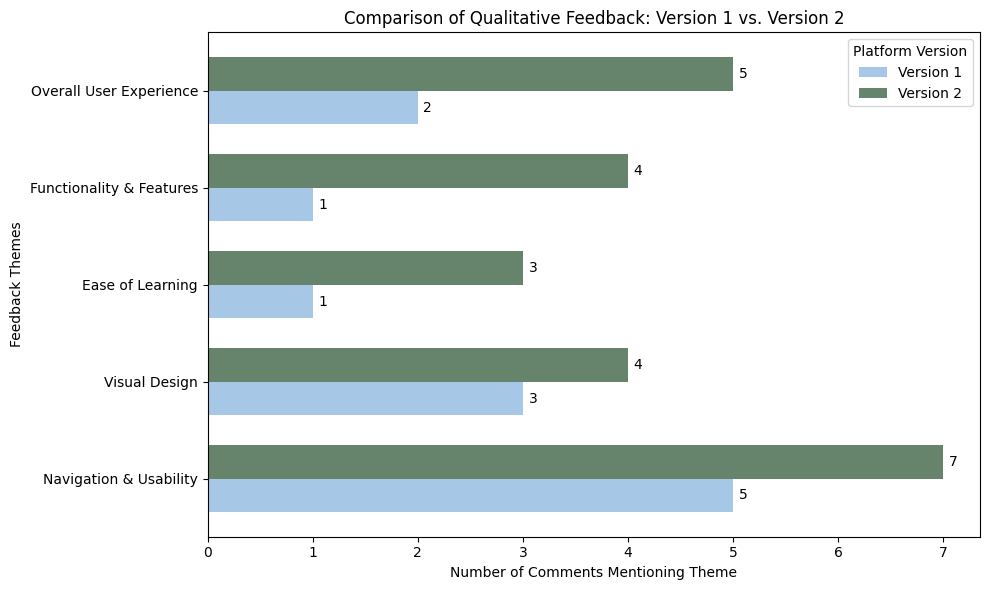

In [ ]:
theme_counts = pd.DataFrame({
    "Version 1": version_1_counts,
    "Version 2": version_2_counts
}, index=themes)

# Plot
ax = theme_counts.plot(
    kind="barh",
    figsize=(10, 6),
    color=["#A7C7E7", "#66836c"],
    width=0.7
)

# Add counts
for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=10)

plt.xlabel("Number of Comments Mentioning Theme")
plt.ylabel("Feedback Themes")
plt.title("Comparison of Qualitative Feedback: Version 1 vs. Version 2")

plt.legend(title="Platform Version")
plt.tight_layout()
plt.show()

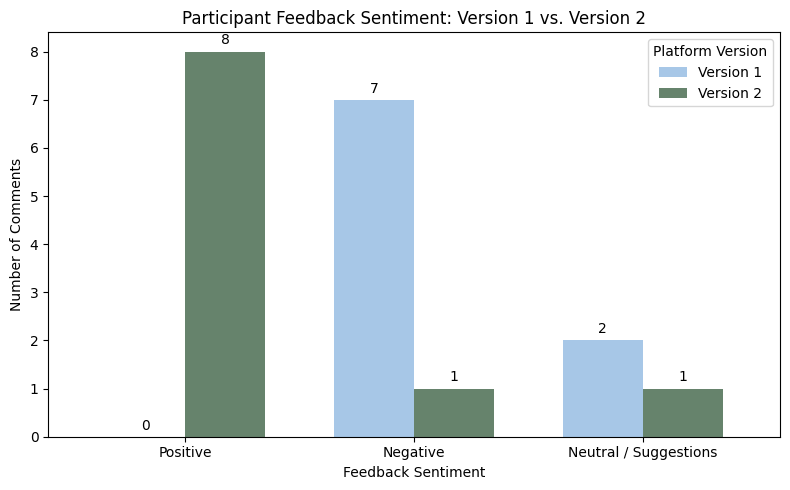

In [ ]:
sentiment_counts = pd.DataFrame({
    "Version 1": [0, 7, 2],
    "Version 2": [8, 1, 1]
}, index=["Positive", "Negative", "Neutral / Suggestions"])

ax = sentiment_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#A7C7E7", "#66836c"],
    width=0.7
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.xlabel("Feedback Sentiment")
plt.ylabel("Number of Comments")
plt.title("Participant Feedback Sentiment: Version 1 vs. Version 2")

plt.xticks(rotation=0)
plt.legend(title="Platform Version")
plt.tight_layout()
plt.show()

In [ ]:
# Display comments from Version 1
comments_task_v1 = version_1_filtered["What obstacle most affected your ability to complete your task?"].dropna()

# Display comments from Version 2
comments_task_v2 = version_2_filtered["What obstacle most affected your ability to complete your task?"].dropna()

print("Version 1 Comments:")
for comment in comments_task_v1:
    print("-", comment)

print("\nVersion 2 Comments:")
for comment in comments_task_v2:
    print("-", comment)

Version 1 Comments:
- Having to figure out on your own on how to use and go through the interface.
- not entirely understanding how to operate it
- How clear the task is
- The structure on the webpage was confusing 
- Couldn't find a way to navigate thru it easily. Than got frustrated and just gave up. Honestly if I had this as an app I would of deleted it seconds into downloading. Really bad app!!!
- I did not understand this page at all. For as much as I tried I did not understand. I felt like it was really confusing.
- hard to navgate
- Too many selections/too many clicks 
- The programming language is restricted to Java.
- It was the appealing process first.
- Not user friendly visually 
- N/a
- No clear markers showing where I need to go 
- N/a
- Font was too small to view
- Hard to see
- Couldn’t navigate 
- no tutorial option
- The better question would be could you complete any task at all! The answer is no! 

Version 2 Comments:
- Just how clear the task was
- Everything was f

In [ ]:
# Qualitative feedback categories
themes = [
    "Navigation Difficulties",
    "Confusing Layout / Organization",
    "Visual Readability",
    "Lack of Guidance",
    "Task Completion Difficulties",
    "Feature / Functionality Concerns",
    "No Obstacles / Positive Experience"
]

version_1_counts = [8, 5, 3, 5, 3, 2, 0]
version_2_counts = [2, 1, 2, 0, 0, 0, 8]

# Create DataFrame
obstacle_counts = pd.DataFrame({
    "Version 1": version_1_counts,
    "Version 2": version_2_counts
}, index=themes)


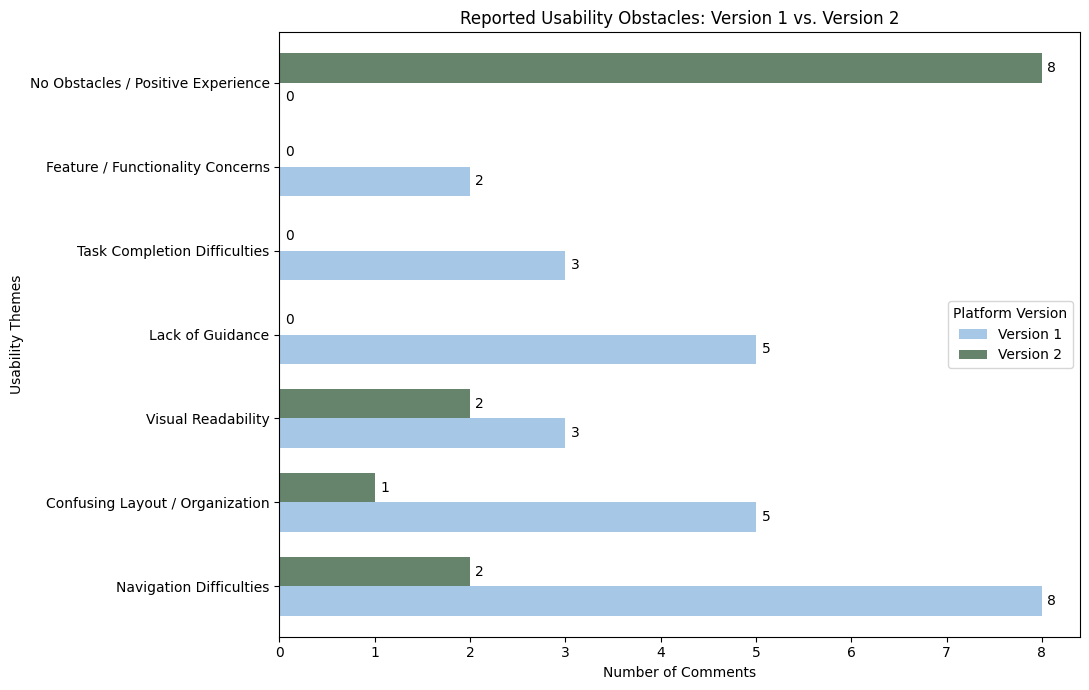

In [ ]:
ax = obstacle_counts.plot(
    kind="barh",
    figsize=(11, 7),
    color=["#A7C7E7", "#66836c"],
    width=0.7
)

# Add counts
for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=10)

plt.xlabel("Number of Comments")
plt.ylabel("Usability Themes")
plt.title("Reported Usability Obstacles: Version 1 vs. Version 2")

plt.legend(title="Platform Version")
plt.tight_layout()
plt.show()
